# Exploring the dataset

In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Polygon, Rectangle

pd.set_option("display.max.columns", None)


In [110]:
data = pd.read_excel("../data-train.xlsx")


In [111]:
print(len(data))
data.tail(3)

309063


,play_id,venue_id,balls,strikes,outs,inning,is_top_inning,pitcher_id,pitcher_hand,batter_id,batter_hand,catcher_id,umpire_id,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success,game_id
309060,tPktCpCH9EUabCZZ,176856,0,0,0,7,False,YDgVbk3N,Left,Q3ePLBpS,Right,LwCLCgVb,75u6eLEW,called_strike,10,6,86.061870,-6.616876,11.815151,-2.386056,4.977449,2.690984,-1.103389,5.683352,-0.458272,1.811175,3.091,1.560,67,1,0,NaN,NaN,92788786
309061,iUFnTD2m2IYTJP0h,176856,0,0,1,7,False,YDgVbk3N,Left,hYHt3D8m,Right,LwCLCgVb,75u6eLEW,called_strike,10,6,87.908849,-9.583004,12.069515,-2.527236,4.887739,3.256083,-0.945678,5.718516,-0.319674,1.976115,3.299,1.665,68,1,0,NaN,NaN,92788786
309062,zoiUws2EifXJQSe1,176856,0,0,2,8,False,YDgVbk3N,Left,XSYK7A24,Left,LwCLCgVb,75u6eLEW,called_strike,10,6,85.605741,-9.400692,15.879488,-2.740557,4.634969,3.259202,-0.031162,5.624634,-0.508776,2.682380,3.244,1.637,75,1,0,NaN,NaN,92788786


In [112]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 309063 entries, 0 to 309062
Data columns (total 34 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   play_id           309063 non-null  str    
 1   venue_id          309063 non-null  int64  
 2   balls             309063 non-null  int64  
 3   strikes           309063 non-null  int64  
 4   outs              309063 non-null  int64  
 5   inning            309063 non-null  int64  
 6   is_top_inning     309063 non-null  bool   
 7   pitcher_id        309063 non-null  str    
 8   pitcher_hand      309063 non-null  str    
 9   batter_id         309063 non-null  str    
 10  batter_hand       309063 non-null  str    
 11  catcher_id        309063 non-null  str    
 12  umpire_id         309063 non-null  str    
 13  pitch_result      309063 non-null  str    
 14  pre_score_home    309063 non-null  int64  
 15  pre_score_away    309063 non-null  int64  
 16  velocity          308623 non-nu

In [113]:
data.describe()

,venue_id,balls,strikes,outs,inning,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,is_success,game_id
count,309063.000000,309063.000000,309063.000000,309063.000000,309063.000000,309063.000000,309063.000000,308623.000000,308623.000000,308623.000000,308623.000000,308623.000000,309060.000000,309060.000000,308623.000000,308623.000000,308623.000000,309063.000000,309063.000000,309063.000000,309063.000000,309063.000000,8329.000000,3.090630e+05
mean,563043.598295,0.803788,0.704232,0.966292,4.898881,2.529099,2.873485,88.407587,1.943712,7.293629,0.975963,5.724643,-1.289673,-1.022248,5.806562,-0.068135,2.334942,3.203481,1.616269,39.763550,2.586136,0.026949,0.491896,5.078045e+07
std,306656.573597,0.961963,0.798496,0.818973,2.556849,2.862809,3.089702,6.008707,10.322131,8.258016,1.820625,0.504919,2.538775,1.573596,0.426985,0.997667,1.089271,0.105567,0.053232,23.276732,1.594433,0.161935,0.499964,2.857648e+07
min,3130.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,31.797467,-28.397298,-23.941868,-4.897896,2.655380,-9.451565,-8.190871,2.569254,-7.042846,-3.542200,2.898000,1.390000,1.000000,1.000000,0.000000,0.000000,7.484900e+04
25%,314611.000000,0.000000,0.000000,0.000000,3.000000,0.000000,0.000000,84.072172,-5.921793,1.997928,0.541422,5.457581,-3.091211,-2.125089,5.535951,-0.811596,1.549440,3.128000,1.578000,20.000000,1.000000,0.000000,0.000000,2.575202e+07
50%,581266.000000,0.000000,0.000000,1.000000,5.000000,2.000000,2.000000,89.306872,2.607234,7.578719,1.581465,5.774366,-1.830947,-1.070269,5.816094,-0.087139,2.290829,3.200000,1.615000,39.000000,2.000000,0.000000,0.000000,5.177432e+07
75%,852995.000000,1.000000,1.000000,2.000000,7.000000,4.000000,4.000000,93.191042,10.806241,14.278078,2.178093,6.063647,0.044806,-0.007337,6.083695,0.679210,3.107548,3.267000,1.649000,59.000000,4.000000,0.000000,1.000000,7.511543e+07
max,997793.000000,3.000000,2.000000,2.000000,13.000000,20.000000,23.000000,103.630975,58.430189,61.397363,5.183731,8.023792,8.721510,22.829628,14.312217,4.926893,17.954397,3.688000,1.803000,116.000000,15.000000,1.000000,1.000000,9.998855e+07


In [114]:
data["is_challenge"].value_counts()

is_challenge
0    300734
1      8329
Name: count, dtype: int64

# Creating new features "challenges_available_for_home/away"

We can figure out the order of events for a particular game by sorting all events of the game by pa_of_game, then by pitch_of_pa. We will then count the number of challenges they had available for that pitch, accounting for extra innings (every extra inning a team gets an extra challenge, capped at 2). We count the number of challenges available for the home/away team as challenges_available_for_home/away.

In [115]:
# replay each game pitch by pitch: sort by plate appearance, then pitch within the plate appearance.
# sorted on a copy, so data keeps its original row order
games = data.sort_values(["game_id", "pa_of_game", "pitch_of_pa"])

# only a failed challenge uses one up (a successful one is kept).
# the hitting team is the away team in the top of an inning, so the home team challenged if (top) == (pitching team)
lost = ((games["is_challenge"] == 1) & (games["is_success"] == 0)).to_numpy()
by_home = (games["is_top_inning"] == (games["challenge_source"] == "pitching_team")).to_numpy()

available = np.empty((len(games), 2), dtype="int64")  # [home, away], before each pitch is (possibly) challenged
game = None
for i, (g, inning) in enumerate(zip(games["game_id"].to_numpy(), games["inning"].to_numpy())):
    if g != game:  # new game: each team starts with 2
        game, current_inning, left = g, inning, [2, 2]
    elif inning != current_inning:
        current_inning = inning
        if inning > 9:  # every extra inning gives both teams one more, capped at 2
            left = [min(n + 1, 2) for n in left]
    available[i] = left
    if lost[i]:
        left[0 if by_home[i] else 1] -= 1

# assigning a Series lines up on the index, so each value goes back to its own pitch
data["challenges_available_for_home"] = pd.Series(available[:, 0], index=games.index)
data["challenges_available_for_away"] = pd.Series(available[:, 1], index=games.index)
data[["challenges_available_for_home", "challenges_available_for_away"]].value_counts()

challenges_available_for_home  challenges_available_for_away
2                              2                                135143
1                              2                                 45883
2                              1                                 44817
1                              1                                 30904
0                              1                                 11815
1                              0                                 11810
2                              0                                 11809
0                              2                                 11079
                               0                                  5803
Name: count, dtype: int64

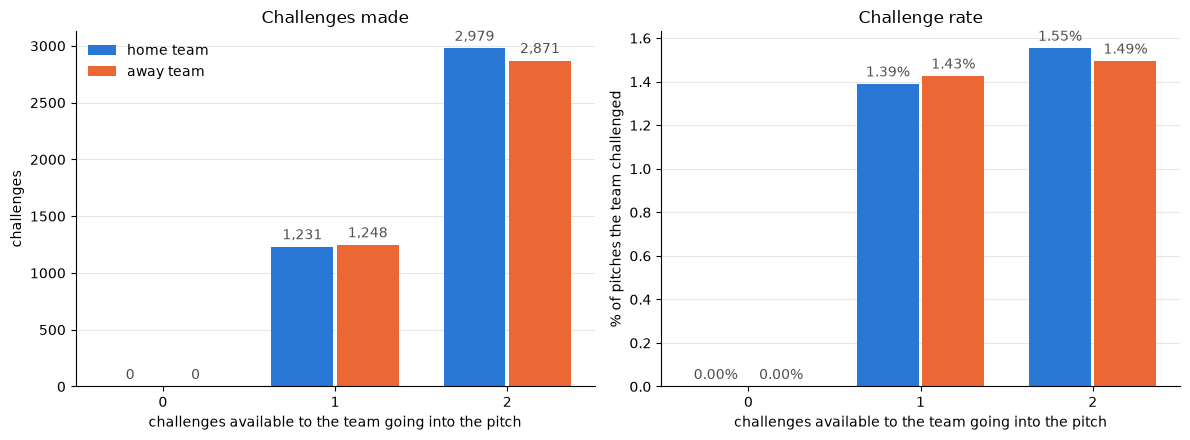

challenges  pitches  challenge rate (%)
available team                                         
0         away           0    29422            0.000000
          home           0    28697            0.000000
1         away        1248    87536            1.425699
          home        1231    88597            1.389438
2         away        2871   192105            1.494495
          home        2979   191769            1.553431

In [126]:
# number of challenges made depending on challenges available
# one row per team per pitch: that team's challenges available going into the pitch, and whether that team
# challenged it (the home team challenged if (top) == (pitching team), as in the cell above)
challenge_made = data["is_challenge"] == 1
home_challenged = challenge_made & (data["is_top_inning"] == (data["challenge_source"] == "pitching_team"))
team_pitches = pd.concat([
    pd.DataFrame({"team": "home", "available": data["challenges_available_for_home"], "challenged": home_challenged}),
    pd.DataFrame({"team": "away", "available": data["challenges_available_for_away"], "challenged": challenge_made & ~home_challenged}),
])
by_available = team_pitches.groupby(["available", "team"])["challenged"].agg(challenges="sum", pitches="size")
by_available["challenge rate (%)"] = by_available["challenges"] / by_available["pitches"] * 100

colors = {"home": "#2a78d6", "away": "#eb6834"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, stat, fmt, title in [(axes[0], "challenges", "{:,.0f}", "Challenges made"),
                             (axes[1], "challenge rate (%)", "{:.2f}%", "Challenge rate")]:
    table = by_available[stat].unstack("team")
    x = np.arange(len(table))
    for offset, team in [(-0.19, "home"), (0.19, "away")]:
        bars = ax.bar(x + offset, table[team], width=0.36, color=colors[team], label=f"{team} team")
        ax.bar_label(bars, fmt=fmt, padding=3, color="#52514e")
    ax.set_xticks(x, table.index)
    ax.set_xlabel("challenges available to the team going into the pitch")
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("challenges")
axes[1].set_ylabel("% of pitches the team challenged")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()
by_available

# Observations

- As expected, teams with no challenges available never challenged.
- Teams were more than twice as likely to challenge when they had 2 challenges available compared only 1 challenge.
- Since challenges are rare, the total challenge rate barely fluctuated regardless of the number of challenges available.

In [116]:
pitch_features = [
    f for f in data.select_dtypes(include="number").columns
    if f not in {"venue_id", "umpire_id", "game_id"}
]

pitch_data = data[pitch_features]
pitch_data.head()

,balls,strikes,outs,inning,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,is_success,challenges_available_for_home,challenges_available_for_away
0,0,0,1,8,4,1,89.460801,16.821696,7.641575,1.574127,4.983008,-4.832515,-0.680814,5.601144,-1.520694,1.963670,3.209,1.619,55,1,0,NaN,2,1
1,2,2,1,3,0,0,87.280420,4.356654,13.543660,1.629416,4.920186,-1.887169,-1.521324,5.629167,0.264480,1.491304,3.226,1.628,19,5,0,NaN,2,2
2,0,0,1,9,11,6,88.743120,1.779116,13.102996,1.596064,5.016592,-2.066066,-1.694117,5.657749,-0.144320,1.486783,3.079,1.554,85,1,0,NaN,0,0
3,0,0,0,8,4,6,88.711556,3.831993,13.076229,1.495055,4.894893,-2.602191,-1.971373,5.599896,-0.577967,1.231735,3.410,1.721,69,1,0,NaN,1,1
4,2,1,1,8,4,1,89.783730,15.221224,8.114938,1.498178,5.007579,-4.388744,-0.150483,5.619921,-1.312273,2.538484,3.209,1.619,55,4,0,NaN,2,1


In [117]:
pitch_data.corr(method="pearson")[["is_challenge","is_success"]].sort_values(by="is_challenge", ascending=False)

,is_challenge,is_success
is_challenge,1.000000,NaN
pitch_of_pa,0.067070,-0.137302
balls,0.056917,-0.094870
strikes,0.051033,-0.133897
inning,0.018897,-0.065536
velocity,0.018765,0.000864
pa_of_game,0.018016,-0.067005
challenges_available_for_home,0.017249,0.013582
challenges_available_for_away,0.014428,0.020007
pre_score_home,0.009116,-0.038956


We see that no feature directly correlates to is_challenge or is_success, suggesting logistic regression probably won't work well.

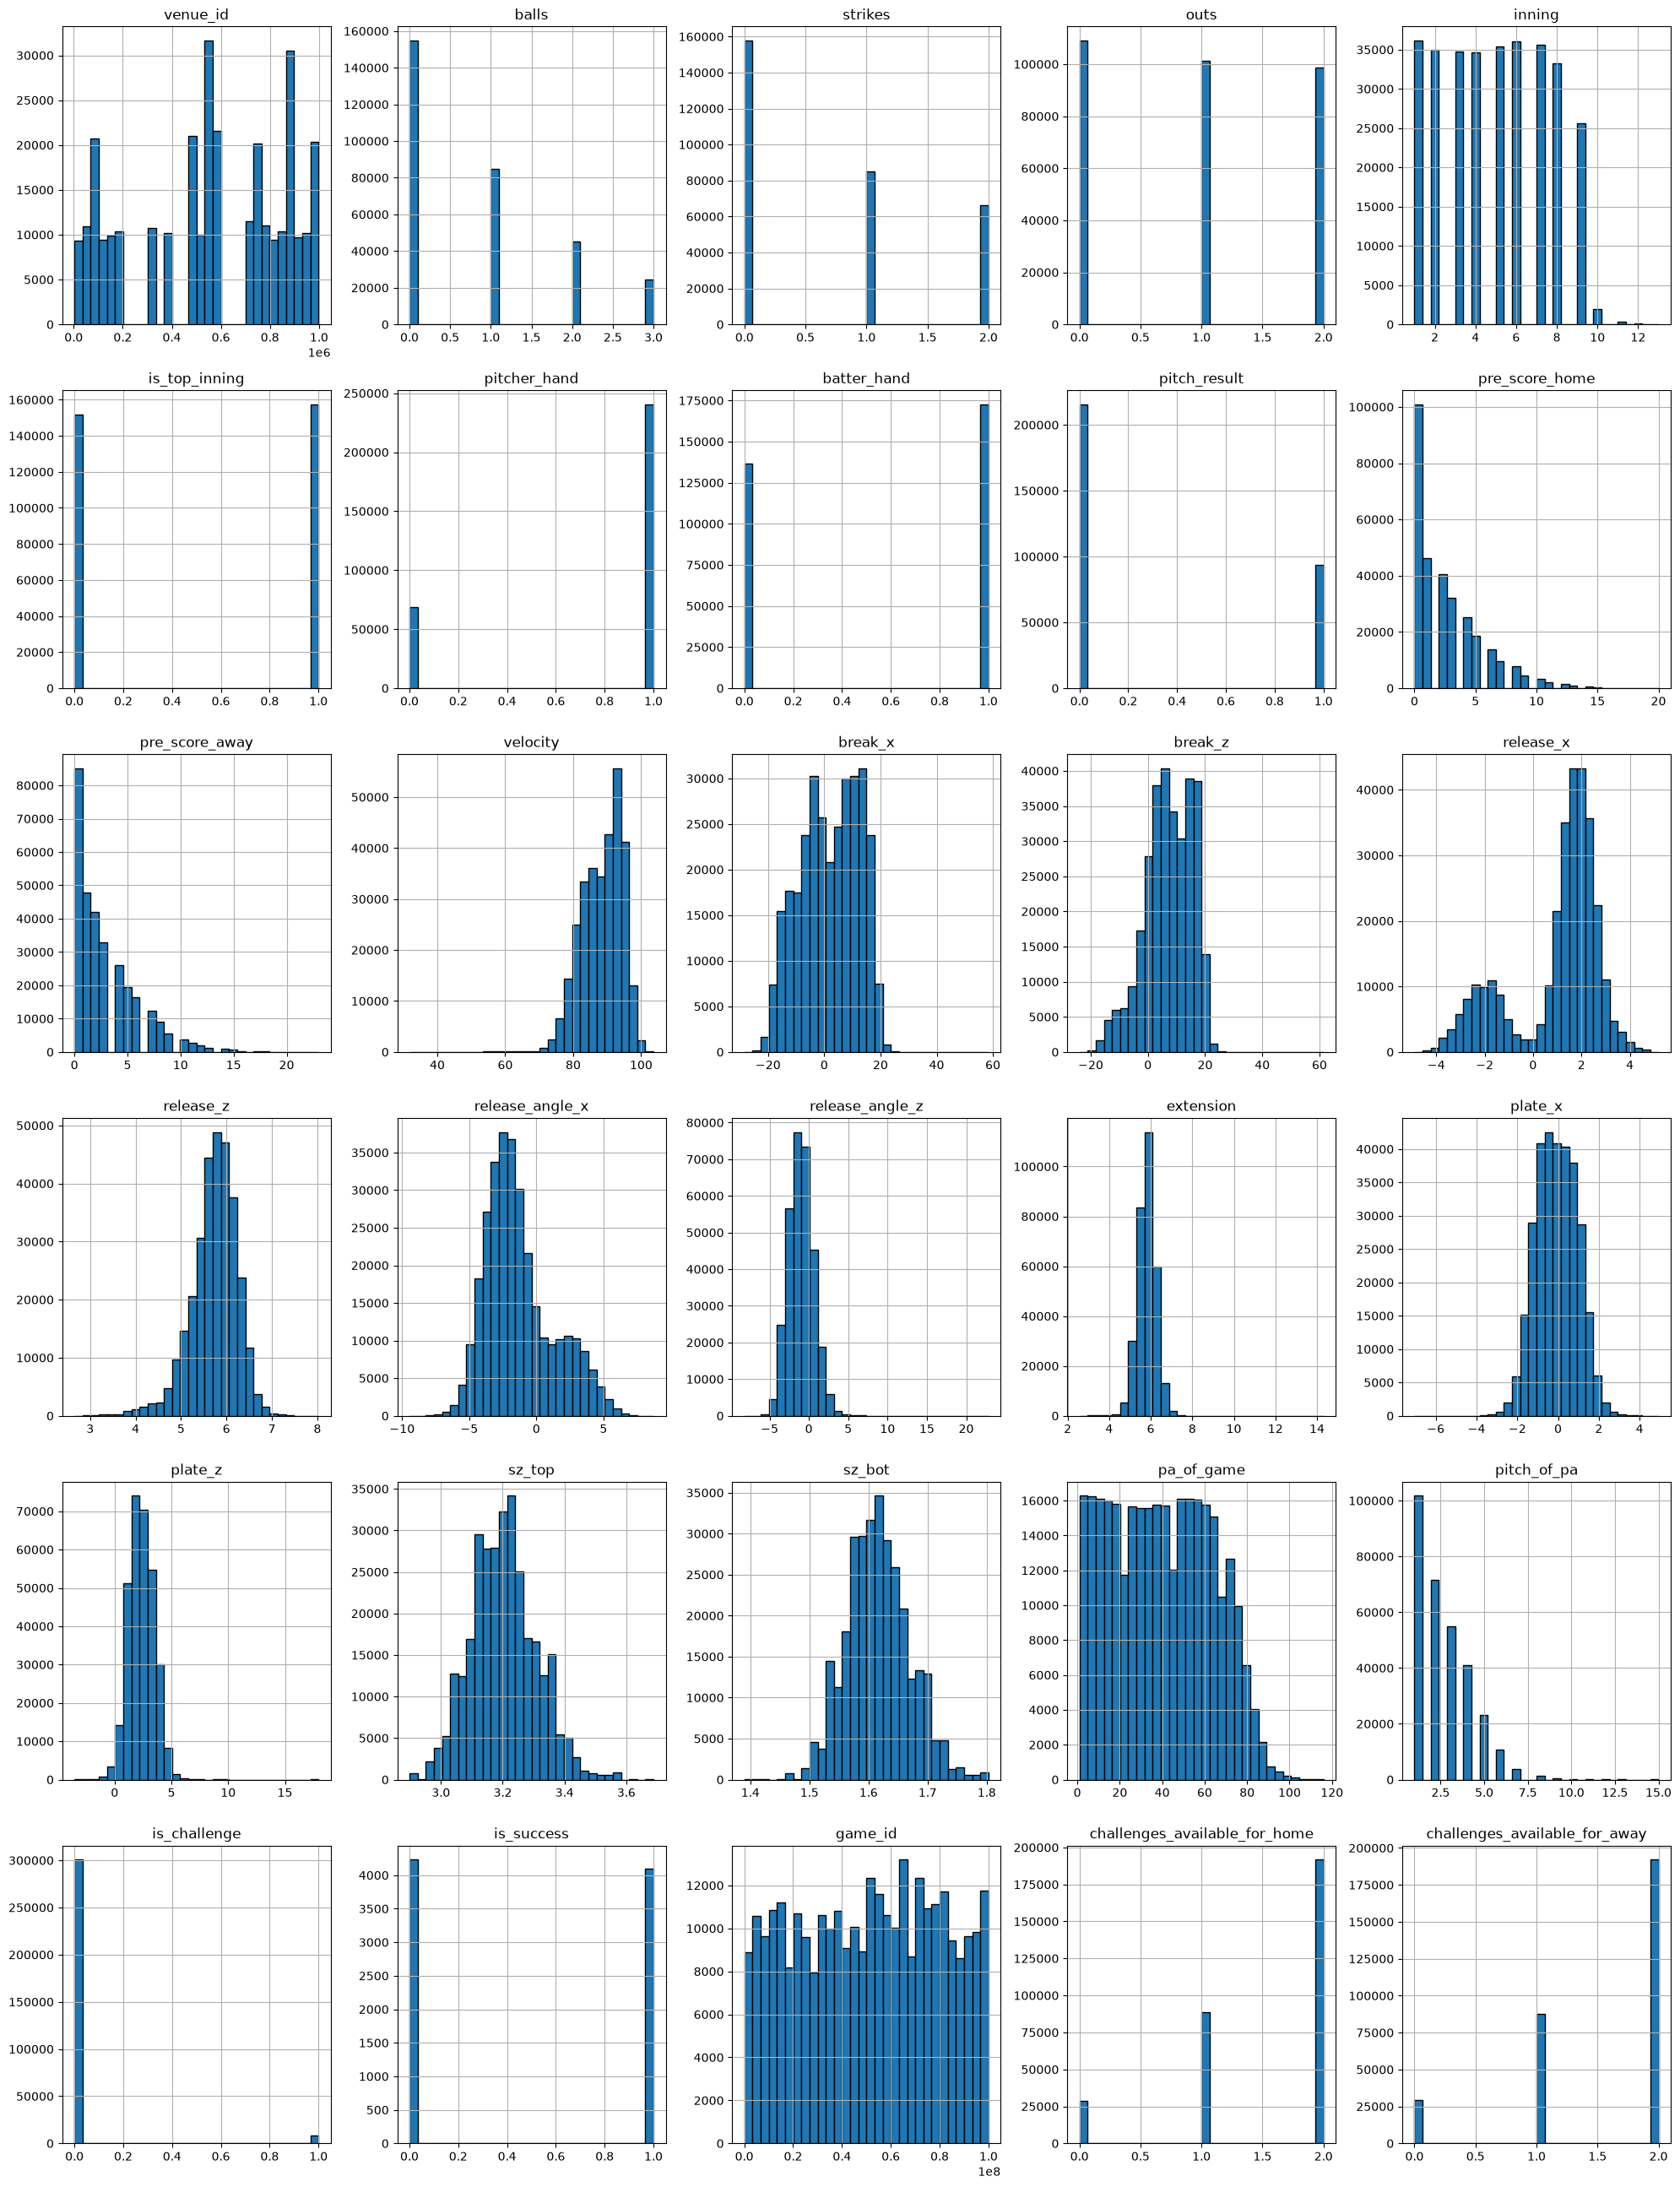

In [118]:
# relabel binary features
positive_values = {
    "is_top_inning": True,
    "pitcher_hand": "Right",
    "batter_hand": "Right",
    "pitch_result": "called_strike",
}
relabeled_data = data.copy()

for f, positive in positive_values.items():
    relabeled_data[f] = (relabeled_data[f] == positive).astype("int64")
relabeled_data.hist(figsize=(20, 26), bins=30, layout=(-1, 5), edgecolor="black")
plt.tight_layout()
plt.show()

# Observations
- Most pitchers are right handed.
- There are slightly more right handed batters than left handed ones.
- release_x, release_angle_x look bimodal, which make sense as horizontal release coordinates and angles are flipped for right handed vs left handed pitchers.
- The vast majority of pitches are not challenged. In fact, only about 2.7% of all pitches are actually challenged.
- Given a call is indeed challenged, just less than half of the calls actually get overturned.

In [119]:
given_challenge = data[pitch_data["is_challenge"]==1]
print(len(given_challenge))
given_challenge.head()

8329


,play_id,venue_id,balls,strikes,outs,inning,is_top_inning,pitcher_id,pitcher_hand,batter_id,batter_hand,catcher_id,umpire_id,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success,game_id,challenges_available_for_home,challenges_available_for_away
21,xK9yzO1PMShacZy5,885087,2,2,2,9,True,AOFhIJmN,Right,JorWsfM3,Right,S9mCZLBI,GmYKfLCG,called_strike,6,3,87.752120,3.628345,12.680988,1.538168,4.893047,-1.529497,-0.729674,5.446059,0.440179,2.155370,3.344,1.688,74,5,1,hitting_team,0.0,10508864,1,2
68,T5gdAtP1J3E7cymt,885087,1,1,0,9,True,AOFhIJmN,Right,idybvU0c,Right,S9mCZLBI,VvwVzldT,called_strike,8,4,89.562322,16.488701,9.079635,1.475463,5.076874,-3.185333,-1.475181,5.690820,-0.105933,1.438055,3.214,1.622,72,3,1,hitting_team,1.0,70596531,2,1
69,xsPqos2jyDR0SARM,885087,0,0,0,9,True,AOFhIJmN,Right,idybvU0c,Right,S9mCZLBI,VvwVzldT,called_strike,8,4,89.982638,18.567762,5.507758,1.617036,5.033417,-3.060257,0.915572,5.631256,0.315047,3.333370,3.214,1.622,72,1,1,hitting_team,1.0,70596531,2,1
88,P23uHQsqMhAuC4zF,901248,1,2,1,8,False,AOFhIJmN,Right,7a2X3GFJ,Left,IML0r71A,GbRL4YRz,called_strike,3,3,90.394122,17.373805,9.024242,1.509568,5.071255,-3.840544,-0.912275,5.527856,-0.676132,2.136581,3.479,1.756,61,5,1,hitting_team,0.0,30505982,2,1
94,9O6o95J4SY1ALBez,491167,1,1,2,8,False,AOFhIJmN,Right,GY7eCKtK,Right,S9mCZLBI,vZTudVJV,called_strike,4,6,89.433332,3.361946,13.175525,1.464954,4.959741,-2.715712,-1.152274,5.541360,-0.755602,2.133051,3.181,1.605,70,3,1,hitting_team,0.0,11359429,1,1


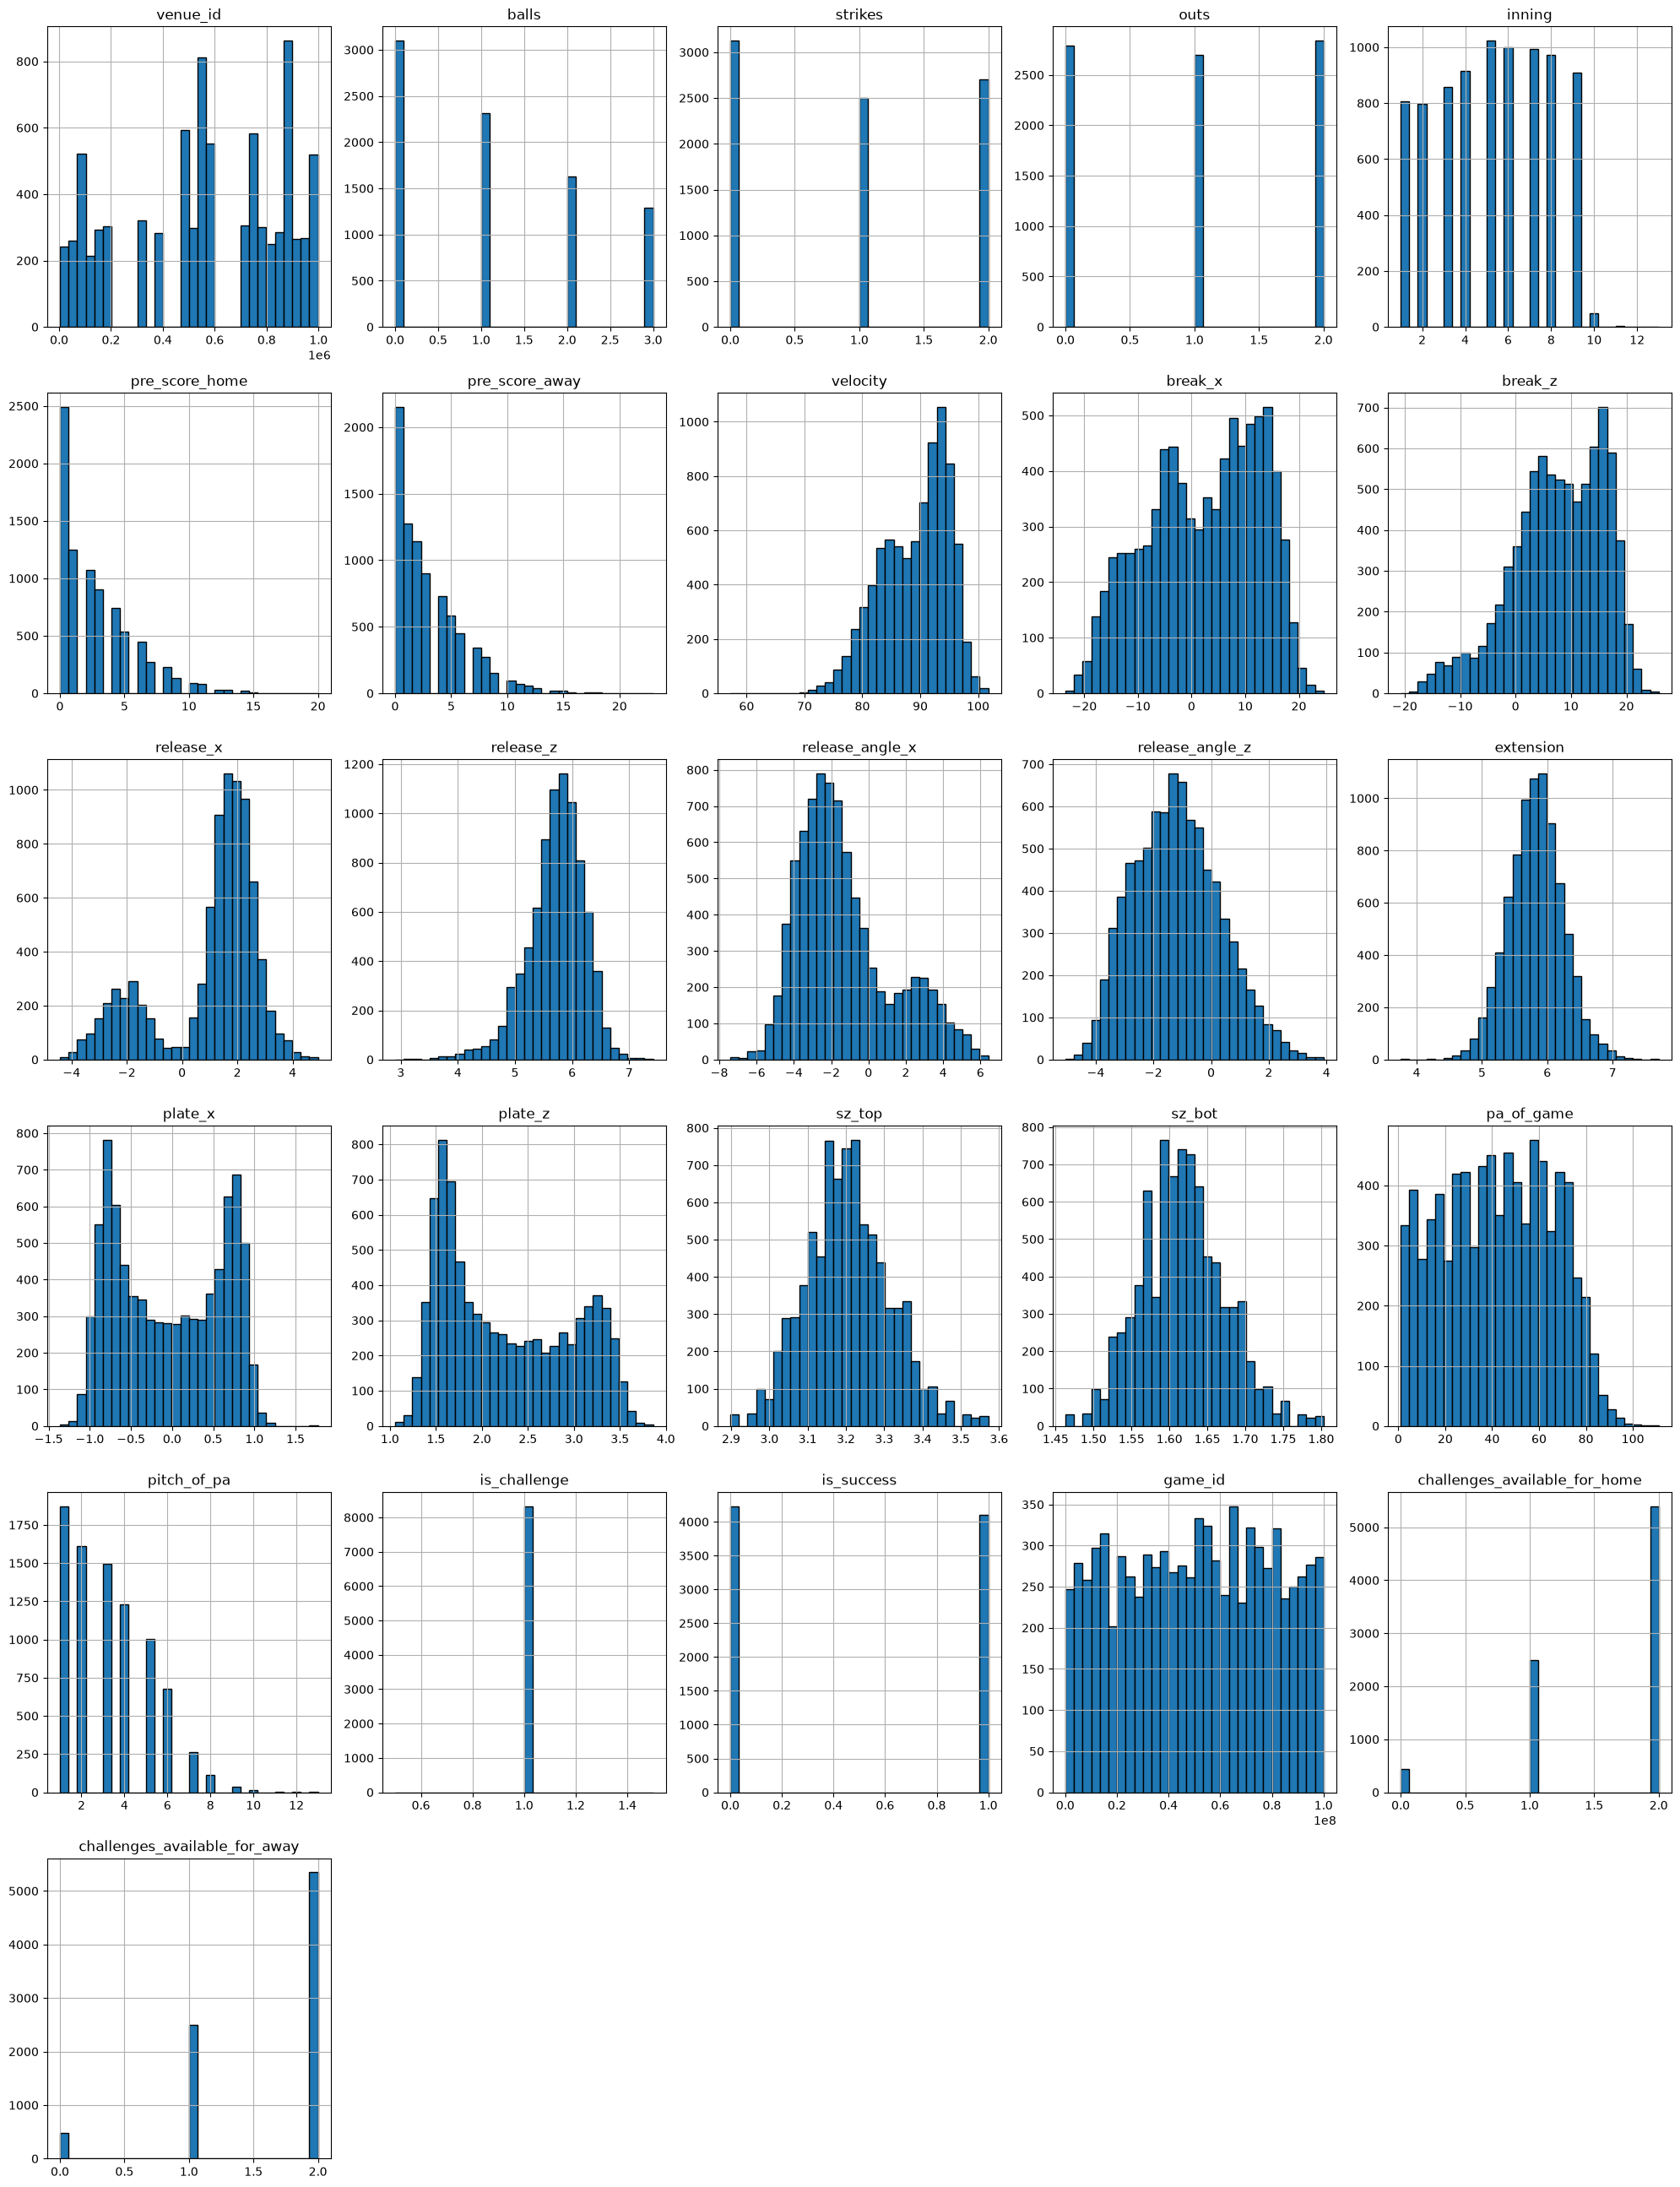

In [120]:
given_challenge.hist(figsize=(20, 26), bins=30, layout=(-1, 5), edgecolor="black")
plt.tight_layout()
plt.show()

# Observations

- We see that if we limit our dataset to pitches that were challenged, pitch locations (plate_x, plate_z) cluster around the edges of the zone, which is expected.
- We see that the porportion of pitches on full counts (2 strikes) go up, which is expected as catchers want to challenge close calls to get outs.

In [121]:
given_challenge[given_challenge["pitch_result"]=="called_strike"]["challenge_source"].value_counts()

challenge_source
hitting_team     4028
pitching_team      21
Name: count, dtype: int64

# Anomalous Challenges

We expect that if a called strike gets challenged, the challenge source would be "hitting_team" and vice versa. Interestingly, this isn't always the case in the dataset, as shown below. Althought we suspect this is either human error or mislabeling of some sort, we cannot rule out the possibility that this is some strange strategy by the pitching team or the hitting team (though this is a hard strategy to justify). For that reason, we will not rule these challenges out as anomalies.

In [122]:
challenges = data[data["is_challenge"] == 1].copy()
pd.crosstab(challenges["challenge_source"], challenges["pitch_result"], margins=True)

pitch_result,ball,called_strike,All
challenge_source,,,
hitting_team,8,4028,4036
pitching_team,4272,21,4293
All,4280,4049,8329


In [123]:
unusual_hitter_challenges = challenges.loc[(challenges["pitch_result"]=="ball") & (challenges["challenge_source"]=="hitting_team")]
unusual_hitter_challenges

,play_id,venue_id,balls,strikes,outs,inning,is_top_inning,pitcher_id,pitcher_hand,batter_id,batter_hand,catcher_id,umpire_id,pitch_result,pre_score_home,pre_score_away,velocity,break_x,break_z,release_x,release_z,release_angle_x,release_angle_z,extension,plate_x,plate_z,sz_top,sz_bot,pa_of_game,pitch_of_pa,is_challenge,challenge_source,is_success,game_id,challenges_available_for_home,challenges_available_for_away
13301,ES95SgfkDeofDuMf,885087,2,2,2,4,True,bIDYvvm3,Right,R9bRe5Ry,Left,IML0r71A,GmYKfLCG,ball,3,8,92.446623,4.307499,17.524714,4.094166,5.468346,-4.000722,-1.141874,5.695289,0.762286,3.043927,3.096,1.563,42,6,1,hitting_team,1.0,24112177,2,2
103748,oS9s7NTc9cMV5jME,382292,0,2,1,2,False,7WSsTVHR,Right,2pZpY515,Left,BDnLP46l,VvwVzldT,ball,2,0,93.803899,17.052926,6.950990,1.406126,5.447151,-3.293030,0.096125,5.697417,-0.242690,3.383696,3.293,1.662,14,3,1,hitting_team,0.0,56863260,2,2
119109,V3mKO7LvWJSmYm6q,581266,3,1,1,4,False,iWer6EBr,Left,zbV7oQ5l,Right,rfW8BcxV,VvwVzldT,ball,1,0,90.416755,-4.426130,10.467089,-2.265584,6.094806,1.944755,-2.178067,5.970030,-0.771730,2.014828,3.223,1.626,27,5,1,hitting_team,1.0,13375320,2,2
168597,HaJkNYvJW0HP9Y3Z,585342,2,2,2,1,True,ArZ5pyPX,Right,iybzsv5M,Left,zkrGGa8L,FfENepDn,ball,0,1,94.105692,1.967826,16.379897,1.940594,6.436613,-3.343622,-2.037182,6.386172,-0.956366,3.207494,3.335,1.683,4,5,1,hitting_team,0.0,87137105,2,2
209448,75EXlsOLMMnyRjrX,565980,1,1,2,3,False,rAzWQxU0,Right,3jiVyTGa,Right,zOMXG6GU,ZbpNT6Xi,ball,0,8,92.549786,13.676165,1.334147,1.752703,5.519390,-3.879577,-1.336867,6.230749,-0.711858,1.638511,3.135,1.582,30,3,1,hitting_team,1.0,71488018,2,2
246450,89fJXExM0kUbd9ex,159969,1,0,1,1,False,5Sukmpns,Right,xAEe4Arx,Left,en4s6yJN,BK80Vj2y,ball,0,0,94.747969,14.659747,7.765874,1.905048,6.183283,-2.956941,-0.767418,5.749204,0.368365,3.411131,3.161,1.595,6,2,1,hitting_team,0.0,19992906,2,2
253481,yjQ2uxqqg7ANSbbY,134960,2,2,0,1,True,u0ATjIeu,Left,bhNCMStv,Right,NRMeij4q,RdZjDQuQ,ball,0,0,92.589669,-5.617282,18.691214,-0.881737,5.806301,1.372625,-3.050891,5.634494,-0.003415,1.748444,3.133,1.581,1,5,1,hitting_team,1.0,46130137,2,2
291987,YyAgUBqgtsnQsh5e,885087,3,0,0,8,True,p45adxZy,Right,l168NkZj,Right,Lt1zY28i,BISZ44GA,ball,5,8,99.317123,7.836035,14.801091,1.510878,6.248290,-3.301336,-2.848913,5.995843,-0.863165,2.392355,3.214,1.622,71,4,1,hitting_team,0.0,66310738,2,2


# A Diagram of the Strike Zone + axes

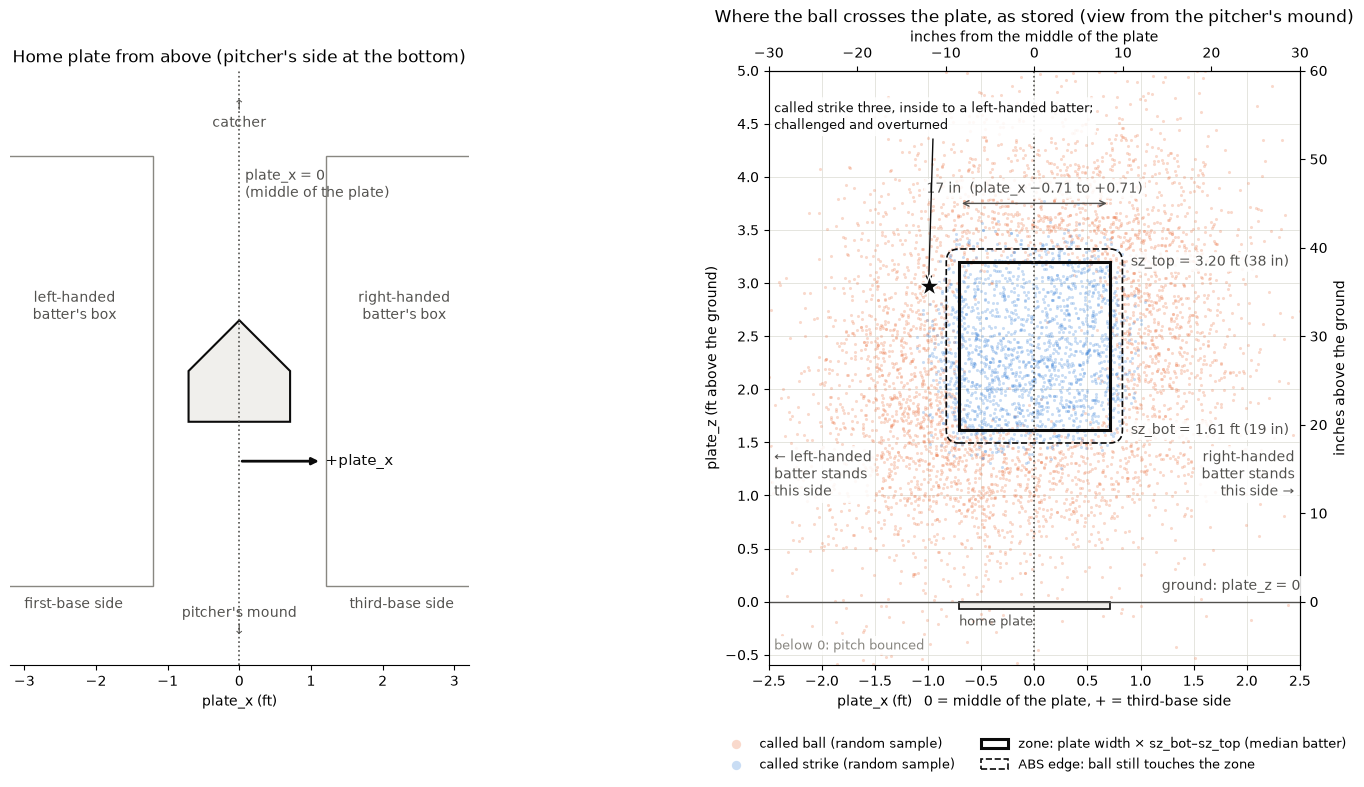

In [124]:
challenged = data[data["is_challenge"] == 1].dropna(subset=["plate_x", "plate_z"])
challenged = challenged.assign(abs_strike=np.where(
    challenged["is_success"] == 1,
    challenged["pitch_result"] == "ball",
    challenged["pitch_result"] == "called_strike",
))
PLATE_HALF = 17 / 2 / 12  # home plate is 17 in wide
BALL_R = 1.45 / 12        # baseball radius (~1.45 in)
sz_top, sz_bot = data["sz_top"].median(), data["sz_bot"].median()
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
BACKING = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.85)
STRIKE, BALL = "#2a78d6", "#eb6834"

fig, (ax_top, ax) = plt.subplots(1, 2, figsize=(16, 8), gridspec_kw={"width_ratios": [1, 1.45]})

# left: home plate from above, drawn from the pitcher's side so +x points right in both panels
ax_top.add_patch(Polygon(
    [(-PLATE_HALF, 0), (PLATE_HALF, 0), (PLATE_HALF, PLATE_HALF), (0, 2 * PLATE_HALF), (-PLATE_HALF, PLATE_HALF)],
    closed=True, fc="#f0efec", ec=INK, lw=1.5,
))
for sign, who in [(1, "right-handed\nbatter's box"), (-1, "left-handed\nbatter's box")]:
    inner = sign * (PLATE_HALF + 0.5)  # boxes start 6 in from the plate, 4 ft wide, 6 ft long
    ax_top.add_patch(Rectangle((min(inner, inner + sign * 4), PLATE_HALF - 3), 4, 6, fill=False, ec=MUTED, lw=1))
    ax_top.text(sign * 2.3, PLATE_HALF + 0.9, who, ha="center", va="center", color=INK2, fontsize=10)
ax_top.axvline(0, color=INK2, ls=":", lw=1.2)
ax_top.text(0.08, 3.55, "plate_x = 0\n(middle of the plate)", color=INK2, fontsize=10, va="top")
ax_top.annotate("", xy=(1.15, -0.55), xytext=(0, -0.55), arrowprops=dict(arrowstyle="-|>", lw=2, color=INK))
ax_top.text(1.2, -0.55, "+plate_x", va="center", fontsize=11, color=INK)
ax_top.text(-3.0, -2.6, "first-base side", color=INK2, fontsize=10)
ax_top.text(3.0, -2.6, "third-base side", color=INK2, fontsize=10, ha="right")
ax_top.text(0, -2.55, "pitcher's mound\n↓", ha="center", va="top", fontsize=10, color=INK2)
ax_top.text(0, 4.05, "↑\ncatcher", ha="center", va="bottom", fontsize=10, color=INK2)
ax_top.set(xlim=(-3.2, 3.2), ylim=(-3.4, 4.9), aspect="equal", xlabel="plate_x (ft)", yticks=[],
           title="Home plate from above (pitcher's side at the bottom)")
for s in ["left", "right", "top"]:
    ax_top.spines[s].set_visible(False)

# right: plate_x / plate_z exactly as stored (+x to the right = seen from the pitcher's mound)
called = data.dropna(subset=["plate_x", "plate_z"]).sample(6000, random_state=67)
for result, color, label in [("ball", BALL, "called ball"), ("called_strike", STRIKE, "called strike")]:
    pts = called[called["pitch_result"] == result]
    ax.scatter(pts["plate_x"], pts["plate_z"], s=5, alpha=0.25, color=color, lw=0, label=f"{label} (random sample)")

ax.axhline(0, color=INK2, lw=1)
ax.add_patch(Rectangle((-PLATE_HALF, -0.07), 2 * PLATE_HALF, 0.07, fc="#f0efec", ec=INK, lw=1.2))
ax.axvline(0, color=INK2, ls=":", lw=1.2)
ax.add_patch(Rectangle((-PLATE_HALF, sz_bot), 2 * PLATE_HALF, sz_top - sz_bot, fill=False, ec=INK, lw=2.2,
                       label="zone: plate width × sz_bot–sz_top (median batter)"))
ax.add_patch(FancyBboxPatch((-PLATE_HALF, sz_bot), 2 * PLATE_HALF, sz_top - sz_bot,
                            boxstyle=f"round,pad={BALL_R},rounding_size={BALL_R}",
                            fill=False, ec=INK, lw=1.2, ls="--", label="ABS edge: ball still touches the zone"))

# dimension labels
ax.annotate("", xy=(-PLATE_HALF, 3.75), xytext=(PLATE_HALF, 3.75), arrowprops=dict(arrowstyle="<->", color=INK2, lw=1))
ax.text(0, 3.82, "17 in  (plate_x −0.71 to +0.71)", ha="center", va="bottom", fontsize=10, color=INK2, bbox=BACKING)
for z, name in [(sz_top, "sz_top"), (sz_bot, "sz_bot")]:
    ax.text(PLATE_HALF + 0.2, z, f"{name} = {z:.2f} ft ({z * 12:.0f} in)", va="center", fontsize=10, color=INK2, bbox=BACKING)
ax.text(1.2, 0.08, "ground: plate_z = 0", fontsize=10, color=INK2, va="bottom", bbox=BACKING)
ax.text(-PLATE_HALF, -0.12, "home plate", fontsize=9, color=INK2, va="top")
ax.text(-2.45, -0.45, "below 0: pitch bounced", fontsize=9, color=MUTED, bbox=BACKING)
ax.text(2.45, 1.0, "right-handed\nbatter stands\nthis side →", ha="right", fontsize=10, color=INK2, bbox=BACKING)
ax.text(-2.45, 1.0, "← left-handed\nbatter stands\nthis side", ha="left", fontsize=10, color=INK2, bbox=BACKING)

# one real pitch for reference
example = data[data["play_id"] == "70bO7L6rjA8k69IU"].iloc[0]
ax.scatter([example["plate_x"]], [example["plate_z"]], marker="*", s=260, color=INK, ec="white", lw=1, zorder=5)
ax.annotate("called strike three, inside to a left-handed batter;\nchallenged and overturned",
            xy=(example["plate_x"], example["plate_z"]), xytext=(-2.45, 4.45), fontsize=9.5, color=INK, bbox=BACKING,
            arrowprops=dict(arrowstyle="->", color=INK, lw=1))

ax.set(xlim=(-2.5, 2.5), ylim=(-0.6, 5.0), aspect="equal",
       xlabel="plate_x (ft)   0 = middle of the plate, + = third-base side",
       ylabel="plate_z (ft above the ground)",
       title="Where the ball crosses the plate, as stored (view from the pitcher's mound)")
ax.set_xticks(np.arange(-2.5, 2.51, 0.5))
ax.set_yticks(np.arange(-0.5, 5.01, 0.5))
ax.grid(color="#e1e0d9", lw=0.6)
ax.set_axisbelow(True)
ax.secondary_xaxis("top", functions=(lambda v: v * 12, lambda v: v / 12)).set_xlabel("inches from the middle of the plate")
ax.secondary_yaxis("right", functions=(lambda v: v * 12, lambda v: v / 12)).set_ylabel("inches above the ground")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9.5, markerscale=3, frameon=False)

plt.tight_layout()
plt.show()

Above is a diagram explaining the coordinate system, along with a spray chart of all pitches colored by their calls by the umpire. We can see that the calls are mostly consistent, with strikes concentrated within the median batter's zone.

In [125]:
import plotly.graph_objects as go
from IPython.display import HTML, display
rest = data[data["is_challenge"] == 0].dropna(subset=["plate_x", "plate_z"]).sample(15000, random_state=67)

# one layer per call and challenge outcome: click a legend entry to show/hide it, double-click to show only that one
calls = {
    "called_strike": ("Called strike", STRIKE, "stayed a strike", "became a ball"),
    "ball": ("Ball", BALL, "stayed a ball", "became a strike"),
}

def abs_edge_text(df):
    # signed distance from each pitch's own ABS edge: its batter's sz_top / sz_bot and the plate, plus the ball's
    # radius, with rounded corners like the dashed outline (a ball exactly on the edge counts as inside)
    dx = df["plate_x"].abs() - PLATE_HALF
    dz = np.maximum(df["plate_z"] - df["sz_top"], df["sz_bot"] - df["plate_z"])
    inches = ((np.hypot(dx.clip(lower=0), dz.clip(lower=0)) + np.minimum(np.maximum(dx, dz), 0) - BALL_R) * 12).round(1)
    return inches.abs().map("{:.1f} in ".format) + np.where(inches > 0, "outside", "inside")

layers = []  # (draw order, legend group, color, name, pitches, marker symbol, size, opacity)
for call, (group, color, upheld, overturned) in calls.items():
    of_call = challenged["pitch_result"] == call
    layers += [
        (0, group, color, "not challenged (random sample)", rest[rest["pitch_result"] == call], "circle", 4, 0.25),
        (1, group, color, f"challenged, {upheld}", challenged[of_call & (challenged["is_success"] == 0)], "circle-open", 6, 0.7),
        (2, group, color, f"challenged, {overturned}", challenged[of_call & (challenged["is_success"] == 1)], "circle", 6, 0.7),
    ]

fig = go.Figure()
# unchallenged pitches first, so the challenged ones are drawn on top
for _, group, color, name, pts, symbol, size, opacity in sorted(layers, key=lambda layer: layer[0]):
    fig.add_trace(go.Scattergl(
        x=pts["plate_x"], y=pts["plate_z"], mode="markers",
        name=f"{name} ({len(pts):,})", legendgroup=group, legendgrouptitle_text=group,
        marker=dict(color=color, symbol=symbol, size=size, opacity=opacity),
        customdata=np.stack([pts["balls"].astype(str) + "-" + pts["strikes"].astype(str), pts["inning"], pts["batter_hand"],
                             abs_edge_text(pts), pts["sz_top"], pts["sz_bot"]], axis=1),
        hovertemplate=(f"{group}, {name}<br>plate_x %{{x:.2f}} ft, plate_z %{{y:.2f}} ft"
                       "<br>count %{customdata[0]}, inning %{customdata[1]}, %{customdata[2]}-handed batter"
                       "<br>ABS edge (this batter's zone): %{customdata[3]}<extra></extra>"),
    ))

# zone for the median batter, and the ABS edge one ball radius outside it
# (WebGL lines, so they are drawn above the WebGL points)
fig.add_trace(go.Scattergl(
    x=[-PLATE_HALF, PLATE_HALF, PLATE_HALF, -PLATE_HALF, -PLATE_HALF], y=[sz_bot, sz_bot, sz_top, sz_top, sz_bot],
    mode="lines", line=dict(color=INK, width=2.5), name="zone (median batter)",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))
arc = np.linspace(0, np.pi / 2, 12)
corners = [(PLATE_HALF, sz_top, 0), (-PLATE_HALF, sz_top, np.pi / 2), (-PLATE_HALF, sz_bot, np.pi), (PLATE_HALF, sz_bot, 1.5 * np.pi)]
edge_x = np.concatenate([cx + BALL_R * np.cos(start + arc) for cx, _, start in corners])
edge_z = np.concatenate([cz + BALL_R * np.sin(start + arc) for _, cz, start in corners])
fig.add_trace(go.Scattergl(
    x=np.append(edge_x, edge_x[0]), y=np.append(edge_z, edge_z[0]),
    mode="lines", line=dict(color=INK, width=1.5, dash="dash"), name="ABS edge",
    legendgroup="Reference", legendgrouptitle_text="Reference", hoverinfo="skip",
))

# ground, home plate, and the middle of the plate
fig.add_hline(y=0, line=dict(color=INK2, width=1))
fig.add_vline(x=0, line=dict(color=INK2, width=1, dash="dot"))
fig.add_shape(type="rect", x0=-PLATE_HALF, x1=PLATE_HALF, y0=-0.07, y1=0, fillcolor="#f0efec", line=dict(color=INK, width=1))
fig.add_annotation(x=2.45, y=1.0, text="right-handed<br>batter's side →", showarrow=False, xanchor="right", font=dict(color=INK2))
fig.add_annotation(x=-2.45, y=1.0, text="← left-handed<br>batter's side", showarrow=False, xanchor="left", font=dict(color=INK2))

fig.update_layout(
    title=dict(text="Pitch locations (view from the pitcher's mound)",
               subtitle=dict(text="Click a legend entry to show or hide it; double-click to show only that one<br>"
                                  "Hover a pitch to see its batter's own zone (green)")),
    width=1000, height=840, plot_bgcolor="white", margin=dict(t=120),
    xaxis=dict(title="plate_x (ft)   0 = middle of the plate, + = third-base side",
               range=[-2.5, 2.5], dtick=0.5, gridcolor="#e1e0d9", zeroline=False),
    yaxis=dict(title="plate_z (ft above the ground)", range=[-0.6, 5.0], dtick=0.5, gridcolor="#e1e0d9",
               zeroline=False, scaleanchor="x", scaleratio=1),
    legend=dict(groupclick="toggleitem", traceorder="grouped"),
)
# hovering a pitch draws its batter's own zone (solid) and ABS edge (dashed) in green; moving off removes them.
# a pitch's sz_top / sz_bot are the last two customdata entries
OWN_ZONE_ON_HOVER = """
const gd = document.getElementById('{plot_id}');
const base = (gd.layout.shapes || []).slice();
const PH = 17 / 24, R = 1.45 / 12, GREEN = '#008300';
function edgePath(top, bot) {
  const pts = [];
  for (const [cx, cz, a0] of [[PH, top, 0], [-PH, top, Math.PI / 2], [-PH, bot, Math.PI], [PH, bot, 1.5 * Math.PI]]) {
    for (let k = 0; k <= 8; k++) {
      const a = a0 + (Math.PI / 2) * k / 8;
      pts.push((cx + R * Math.cos(a)).toFixed(4) + ' ' + (cz + R * Math.sin(a)).toFixed(4));
    }
  }
  return 'M ' + pts.join(' L ') + ' Z';
}
gd.on('plotly_hover', ev => {
  const cd = ev.points[0].customdata;
  if (!cd) return;
  const top = parseFloat(cd[cd.length - 2]), bot = parseFloat(cd[cd.length - 1]);
  Plotly.relayout(gd, {shapes: base.concat([
    {type: 'rect', x0: -PH, x1: PH, y0: bot, y1: top, line: {color: GREEN, width: 2.5}, layer: 'above'},
    {type: 'path', path: edgePath(top, bot), line: {color: GREEN, width: 1.5, dash: 'dash'}, layer: 'above'},
  ])});
});
gd.on('plotly_unhover', () => Plotly.relayout(gd, {shapes: base}));
"""

display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False, post_script=OWN_ZONE_ON_HOVER)))

Above is an interactive showing all the pitches in the dataset. Hovering over, it shows the estimated strikezone adjusted to the individual batter using sz_top and sz_bot.